In [237]:
import matplotlib.pyplot as plt
import torch
from torch import nn
import math
import time
import jcamp
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [168]:
class Denoising1(nn.Module):
    """

    """

    def __init__(
        self,
        depth,
        input_dim, 
        hidden_dims
    ):
        """

        """
        super().__init__()
        
        L = []
        self.depth = depth
        
        prev_dim = input_dim
        for i in range(self.depth):
            L.append(nn.Linear(prev_dim, hidden_dims[i]))
            L.append(nn.ReLU())
            prev_dim = hidden_dims[i]
            
        L.append(nn.Linear(hidden_dims[-1], input_dim)) 
        
        self.L = nn.Sequential(*L)

    def forward(self, x, x_org=None):
        """

        Args:

        Returns:
            loss: A scalar loss
        """

        loss = 0.0
        
        #prev_h = x.clone()
        #for i in range(self.depth):
        #    next_h = self.L[i](prev_h)
        #    prev_h = next_h
        x_ = self.L(x)
        
        if x_org is None:
            loss = torch.norm(
                x - x_
                )
        else:
            loss = torch.norm(
                x_org - x_
                )

        return loss
    
    def sample(self, x):
        """

        Args:

        Returns:
            loss: A scalar loss
        """
        
        #prev_h = x.clone()
        #for i in range(self.depth):
        #    next_h = self.L[i](prev_h)
        #    prev_h = next_h
            
        #x_ = self.L[-1](prev_h)
        x_ = self.L(x)
        
        return x_


In [106]:
conv_1 = nn.Conv1d(1, 3, 3, padding=1)
pool1 = torch.nn.MaxPool1d(2)
conv_2 = nn.Conv1d(3, 9, 3, padding=1)

In [107]:
x = torch.rand(1, 10)

with torch.no_grad():
    y = conv_1(x)
    y = pool1(y)
with torch.no_grad():
    z = conv_2(y)
    z = pool1(z)

In [108]:
x.shape, y.shape, z.shape

(torch.Size([1, 10]), torch.Size([3, 5]), torch.Size([9, 2]))

In [199]:
class Denoising(nn.Module):
    """

    """

    def __init__(
        self,
        #depth,
        #input_dim, 
        #hidden_dims
    ):
        """

        """
        super().__init__()
        
        self.conv1 = nn.Conv1d(1, 64, 3, padding=1)
        self.conv2 = nn.Conv1d(64, 128, 3, padding=1)
        self.conv3 = nn.Conv1d(128, 256, 3, padding=1)
        self.conv4 = nn.Conv1d(256, 512, 3, padding=1)
        self.conv5 = nn.Conv1d(512, 1024, 3, padding=1)
        
        self.ReLU = nn.ReLU()
        self.max_pool = torch.nn.MaxPool1d(2)
        self.avg_pool = torch.nn.MaxPool1d(53)
        self.linear = torch.nn.Linear(1024, 1725)
        

    def forward(self, x, x_org=None):
        """

        Args:

        Returns:
            loss: A scalar loss
        """

        loss = 0.0
        
        out1 = self.conv1(x) 
        out1 = self.ReLU(out1)
        out1 = self.max_pool(out1)
        
        out2 = self.conv2(out1) 
        out2 = self.ReLU(out2)
        out2 = self.max_pool(out2)
        
        out3 = self.conv3(out2) 
        out3 = self.ReLU(out3)
        out3 = self.max_pool(out3)
        
        out4 = self.conv4(out3) 
        out4 = self.ReLU(out4)
        out4 = self.max_pool(out4)
        
        out5 = self.conv5(out4) 
        out5 = self.ReLU(out5)
        out5 = self.max_pool(out5)
        
        out6 = self.avg_pool(out5)
        
        out7 = self.linear(out6[:,:,0])

        if not self.training:
            return out7
        N = x.shape[0]
        if x_org is None:
            loss = torch.norm(
                x - out7
                ) / N
        else:
            loss = torch.norm(
                x_org - out7
                ) / N

        return loss
    
    def sample(self, x):
        """

        Args:

        Returns:
            loss: A scalar loss
        """
        
        #prev_h = x.clone()
        #for i in range(self.depth):
        #    next_h = self.L[i](prev_h)
        #    prev_h = next_h
            
        #x_ = self.L[-1](prev_h)
        x_ = self.L(x)
        
        return x_



In [182]:
x1[0:10,None,:].shape

torch.Size([10, 1, 1725])

In [190]:
model = Denoising()
model.eval()

Denoising(
  (conv1): Conv1d(1, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (conv2): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (conv3): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,))
  (conv4): Conv1d(256, 512, kernel_size=(3,), stride=(1,), padding=(1,))
  (conv5): Conv1d(512, 1024, kernel_size=(3,), stride=(1,), padding=(1,))
  (ReLU): ReLU()
  (max_pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (avg_pool): MaxPool1d(kernel_size=53, stride=53, padding=0, dilation=1, ceil_mode=False)
  (linear): Linear(in_features=1024, out_features=1725, bias=True)
)

In [191]:
with torch.no_grad():
    y = model(x1[0:10,None,:])

In [192]:
y.shape

torch.Size([10, 1725])

In [165]:
model.parameters()

<generator object Module.parameters at 0x7fb383e29460>

In [153]:
def train_denoising(
    model,
    data,
    num_epochs,
    batch_size,
    learning_rate,
    data_org=None,
    lr_decay=1,
    #device: torch.device = torch.device("cpu"),
    device = torch.device("cpu"),
):
    """
    Run optimization to train the model.
    """

    model = model.to(device)
    model.train()

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()), learning_rate
    )
    lr_scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda epoch: lr_decay ** epoch
    )

    # sample minibatch data
    iter_per_epoch = math.ceil(data.shape[0] // batch_size)
    loss_history = []

    for i in range(num_epochs):
        start_t = time.time()
        for j in range(iter_per_epoch):
            
            spectra = (
                data[j * batch_size : (j + 1) * batch_size]
            )
            spectra = spectra.to(device)
            
            if data_org is not None:
                spectra_org = (
                    data_org[j * batch_size : (j + 1) * batch_size]
                )
                spectra_org = spectra_org.to(device)
                loss = model(spectra, spectra_org)
            else:
                loss = model(spectra)
                
            optimizer.zero_grad()
            loss.backward()
            loss_history.append(loss.item())
            optimizer.step()
        end_t = time.time()

        print(
            "(Epoch {} / {}) loss: {:.4f} time per epoch: {:.1f}s".format(
                i, num_epochs, loss.item(), end_t - start_t
            )
        )

        lr_scheduler.step()

    # plot the training losses
    plt.plot(loss_history)
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.title("Training loss history")
    plt.show()
    return model, loss_history

In [238]:
spectra_data = pd.read_csv('spectral_data_all.csv')
spectra_data = spectra_data.query('type_sprectra == "FTIR"').drop(columns='Unnamed: 0')

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_91689/86078379.py:1: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  spectra_data = pd.read_csv('spectral_data_all.csv')


In [240]:
df_spectra_flopp = spectra_data.query('data_source == "flopp" or data_source == "flopp_e"').reset_index(drop=True)
df_spectra_flopp = df_spectra_flopp.query('intensity > 0')
#df_spectra_flopp = norm_spect(df_spectra_flopp, norm_type='SNV')
df_flopp_pivot = df_spectra_flopp.pivot(index=['file_name', 'polymer', 'data_source'], 
               columns='wavelength', 
               values='intensity').reset_index()
wl_list = df_flopp_pivot.columns[3:]
df_flopp_pivot.columns = list(df_flopp_pivot.columns[:3]) + ['wl_' + str(round(x*100)) for x in df_flopp_pivot.columns[3:]]
polymer_list = df_flopp_pivot['polymer'].drop_duplicates().to_numpy()


In [241]:
#df_flopp_pivot.groupby('polymer').count()

In [242]:
#df_flopp_pivot.query('file_name=="PP 1. Red Straw Fragment.CSV"').iloc[0,3:].plot()

In [375]:
df_flopp_pivot

,file_name,polymer,data_source,wl_67499,wl_67692,wl_67885,wl_68078,wl_68271,wl_68463,wl_68656,...,wl_398245,wl_398438,wl_398631,wl_398824,wl_399017,wl_399209,wl_399402,wl_399595,wl_399788,wl_399981
0,ABS 1. Black Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp_e,92.52406,92.33225,91.89323,91.58796,91.34173,90.93127,90.06970,...,98.86223,98.84976,98.84842,98.87078,98.86506,98.86544,98.87539,98.85711,98.85205,98.87262
1,ABS 1. Orange LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,91.82936,91.67874,91.60149,91.38452,91.08202,90.73048,90.19894,...,99.99870,99.98991,100.02670,100.04670,100.04430,100.06880,100.07030,100.03320,100.02030,100.04200
2,ABS 10. Brown LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,87.53708,87.35301,87.08498,86.78752,86.39802,85.75906,84.95250,...,100.32650,100.31270,100.36010,100.39630,100.38240,100.36540,100.36210,100.36500,100.37590,100.37630
3,ABS 11. Black LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,89.22928,89.05251,88.92063,88.62650,88.32430,87.79993,86.99644,...,99.72849,99.69849,99.72910,99.76530,99.78951,99.79996,99.79977,99.76286,99.73790,99.74247
4,ABS 12. White LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,78.51719,78.51464,78.53676,78.48975,78.21510,77.90458,77.44738,...,98.46631,98.44939,98.49831,98.54372,98.53715,98.51609,98.51604,98.50509,98.49593,98.49917
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,R 5. Black Michelin Tire Fragment.CSV,Rubber,flopp,84.55315,84.26257,84.13648,84.05460,83.82146,83.58154,83.33791,...,96.04444,96.04410,96.03255,96.02443,96.03119,96.03701,96.04668,96.05433,96.05984,96.05284
377,R 6. Black Bike Tire Fragment.CSV,Rubber,flopp,96.87849,96.80142,96.77434,96.81955,96.72005,96.61556,96.45898,...,99.18976,99.16830,99.19671,99.22066,99.21915,99.20261,99.21185,99.22159,99.21061,99.21214
378,R 8. White Bike Tire Fragment.CSV,Rubber,flopp,72.18967,72.43279,72.63416,72.82638,72.92630,73.13307,73.29342,...,101.66650,101.65600,101.65900,101.64850,101.63790,101.63070,101.62330,101.61570,101.61060,101.59380
379,R 9. Grey Rubber Fragment.CSV,Rubber,flopp,77.21106,78.14238,78.29487,78.44791,78.53461,78.56750,78.51958,...,99.69334,99.70274,99.71629,99.72917,99.74500,99.74796,99.74181,99.73234,99.72741,99.71638


In [376]:
x1 = df_flopp_pivot.query('data_source == "flopp" and polymer=="Polypropylene"').iloc[:,3:].to_numpy()
x1_e = df_flopp_pivot.query('data_source == "flopp_e" and polymer=="Polypropylene"').iloc[:,3:].to_numpy()
x2 = df_flopp_pivot.query('polymer=="Polyethylene"').iloc[:,3:].to_numpy()
t = np.array(wl_list)

In [377]:
x_1_norm = (x1 - x1.min(1)[:,None]) / (x1.max(1)[:,None] - x1.min(1)[:,None])

mu_1 = x_1_norm.mean(0)
std_1 = x_1_norm.std(0)

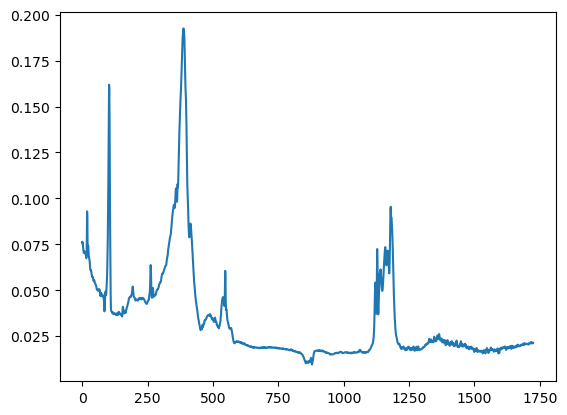

In [378]:
plt.plot(std_1)

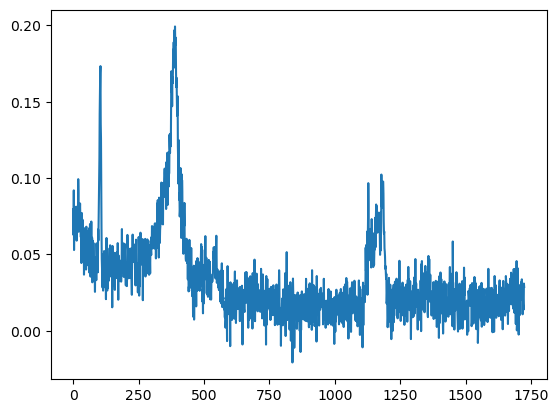

In [379]:
plt.plot(np.random.normal(std_1,.01))

In [372]:
np.random.binomial(p=std_1,n=1)

array([0, 0, 0, ..., 0, 0, 0])

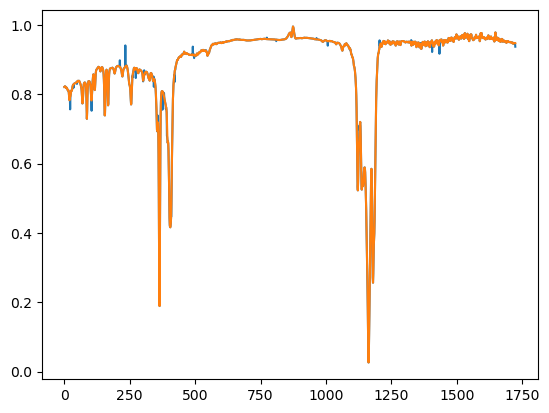

In [384]:
spec_rand = np.random.normal(mu_1, np.random.binomial(p=std_1,n=1)*.02)
plt.plot(spec_rand)
plt.plot(mu_1)

In [397]:
np.diff(wl_list.to_numpy(),1)

array([1.9284999999999854, 1.9285999999999603, 1.928600000000074, ...,
       1.9279999999998836, 1.9290000000000873, 1.9290000000000873],
      dtype=object)

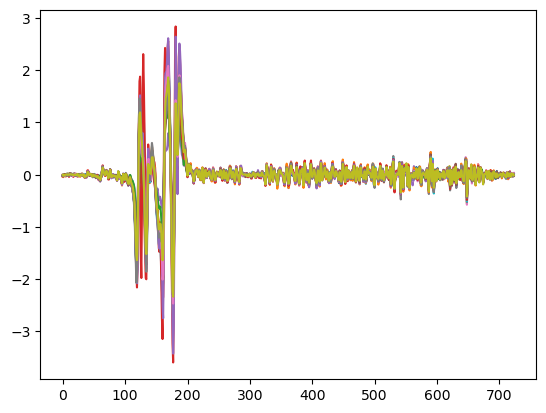

In [404]:
plt.plot((np.diff(x1,1,1).T)[1000:])

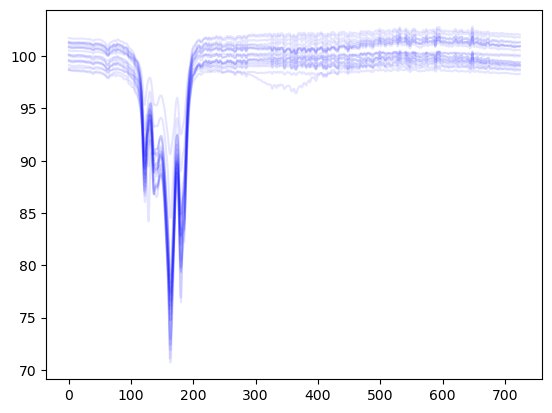

In [403]:
plt.plot((x1.T)[1000:], c='b', alpha=.1)

In [275]:
x1 - x1.min(1)[:,None]

array([[23.80195, 23.81305, 23.90908, ..., 24.79411, 24.80391, 24.82661],
       [19.7396 , 19.74239, 19.95011, ..., 21.23672, 21.22882, 21.23737],
       [18.13062, 18.08199, 18.19487, ..., 23.44598, 23.45918, 23.46948],
       ...,
       [20.75003, 20.82481, 20.90828, ..., 23.36169, 23.34316, 23.36024],
       [12.88405, 12.87766, 12.94425, ..., 20.51188, 20.5061 , 20.50703],
       [19.76432, 19.91679, 20.02271, ..., 25.73499, 25.75239, 25.74119]])

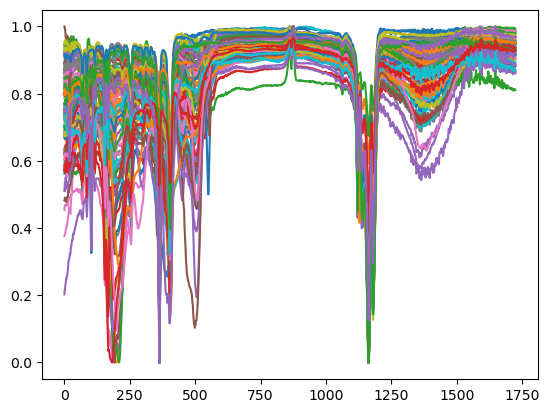

In [276]:
plt.plot(((x1 - x1.min(1)[:,None]) / (x1.max(1)[:,None] - x1.min(1)[:,None])).T)

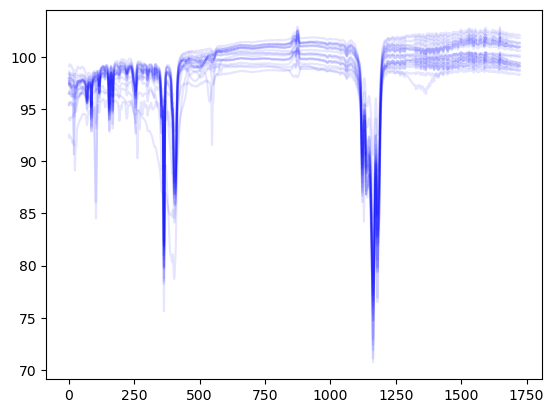

In [401]:
plt.plot(x1.T, c='b', alpha=.1)
#plt.plot(x1_e.T, c='r', alpha=.1)

In [158]:
x1 = torch.tensor(np.float64(x1)).type(torch.FloatTensor)
x2 = torch.tensor(np.float64(x2)).type(torch.FloatTensor)

In [159]:
x = np.concatenate([x1,x2])

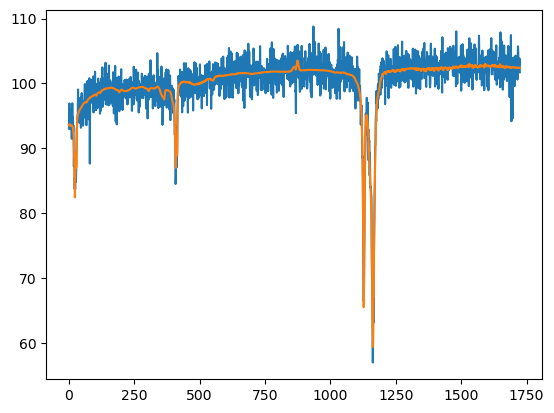

In [160]:
#x = df_flopp_pivot.iloc[:,3:].to_numpy()
t = np.array(wl_list)

n = x.shape[0]

def spectr_pert(x, t):
    noise = np.random.normal(np.zeros(x.shape[0]), np.random.rand(x.shape[0]) / 2 * x.std(1), size=(1725, n)).T

    jumps_n = np.random.poisson(5, size = (n))
    jumps_loc = [np.random.choice(1725, jumps_n[i]) for i in range(n)]
    jumps = np.zeros((n, 1725))

    #poly = np.zeros((381, 1725))
    #for d in range(poly_degree + 1):
    #     poly = np.power(t, d)*poly_coef[0]
    poly_degree = np.random.randint(10)
    poly_coef = 10*(2*np.random.rand(poly_degree+1)-1) # each?
    #t = np.array(wl_list)
    t = (t-t.min())/(t.max()-t.min())
    #t = t / t.max()
    poly = np.power(np.concatenate([t[:,None]] * (poly_degree+1), 1), range(poly_degree+1))
    poly = (poly * poly_coef).sum(1)

    for i in range(n):
        jumps[i, jumps_loc[i]] = 20*np.random.exponential(1)

    x_ = x + noise - jumps# + poly
    return x_

x_ = spectr_pert(x, t)
#x_ = (x_ - x_.max())/(x_.min() - x_.max())
plt.plot(x_[100])
plt.plot(x[100])

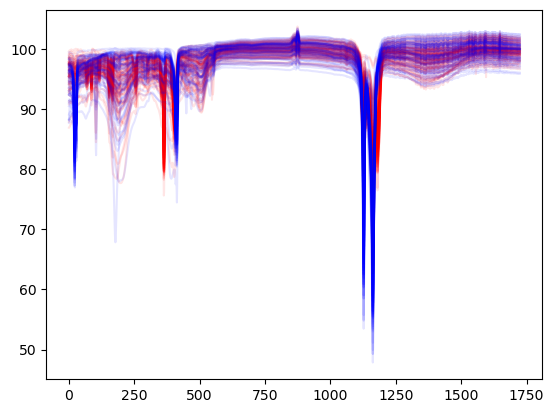

In [12]:
_=plt.plot(x1.T, c='r', alpha=.1)
_=plt.plot(x2.T, c='b', alpha=.1)

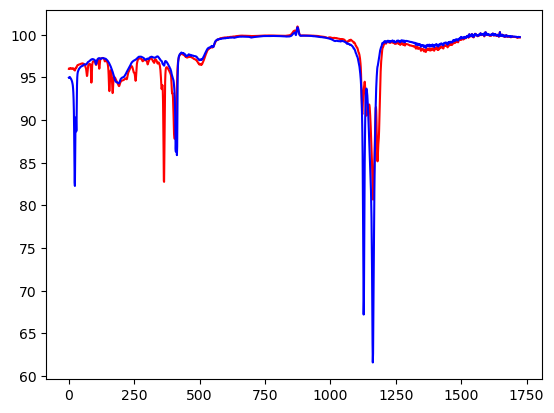

In [13]:
_=plt.plot(x1.mean(0), c='r')
_=plt.plot(x2.mean(0), c='b')

In [161]:
x_ = np.concatenate([spectr_pert(x, t) for i in range(10)])
x_ = torch.tensor(np.float64(x_)).type(torch.FloatTensor)

In [162]:
x_org = np.concatenate([x for i in range(10)])
x_org = torch.tensor(np.float64(x_org)).type(torch.FloatTensor)

In [79]:
#x = torch.tensor(np.float64(x)).type(torch.FloatTensor)

In [169]:
#h_dim = [1000, 400,300,200,100,50,100,200,300,400, 1000]
#h_dim = [1700,800, 1700]
#h_dim = [1725,1725,1725,1725,1725]
#h_dim = [3*1725,2*1725,1725,2*1725,3*1725]
h_dim = [1500,1000,400,300,200,100,50,100,200,300,400, 1000, 1500]

model = Denoising1(
    depth=len(h_dim),
    input_dim=1725, 
    hidden_dims=h_dim
)

In [200]:
model = Denoising()

In [197]:
x_[:,None,:].shape

torch.Size([1520, 1, 1725])

(Epoch 0 / 10) loss: 3769.1340 time per epoch: 28.3s
(Epoch 1 / 10) loss: 1769.0000 time per epoch: 28.8s
(Epoch 2 / 10) loss: 347.3657 time per epoch: 30.1s
(Epoch 3 / 10) loss: 898.8357 time per epoch: 30.4s
(Epoch 4 / 10) loss: 1137.7191 time per epoch: 30.8s
(Epoch 5 / 10) loss: 304.2090 time per epoch: 32.2s
(Epoch 6 / 10) loss: 201.6180 time per epoch: 33.8s
(Epoch 7 / 10) loss: 138.9821 time per epoch: 31.1s
(Epoch 8 / 10) loss: 496.1897 time per epoch: 33.4s
(Epoch 9 / 10) loss: 381.4425 time per epoch: 33.8s


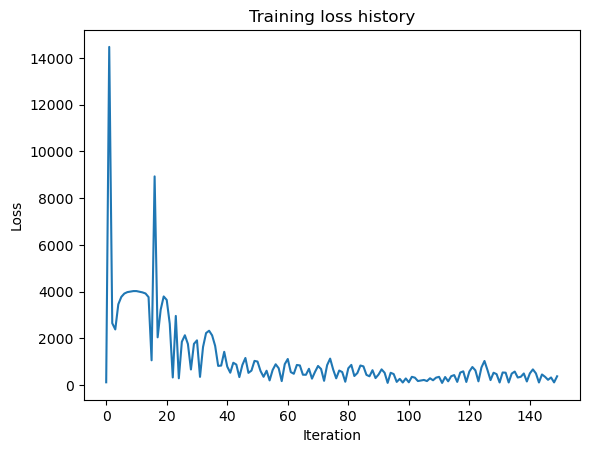

In [218]:
trained_model, loss_model = train_denoising(
        model,
        x_[:,None,:],
        data_org=x_org[:,None,:],
        num_epochs=10,
        batch_size=100,
        learning_rate=0.01
        #device=DEVICE,
    )

In [204]:
x1[:,None,:].shape

torch.Size([85, 1, 1725])

In [219]:
model.eval()
with torch.no_grad():
    x1_out = model(x1[:,None,:])
    x2_out = model(x2[:,None,:])
    x_out = model(x_[:,None,:])

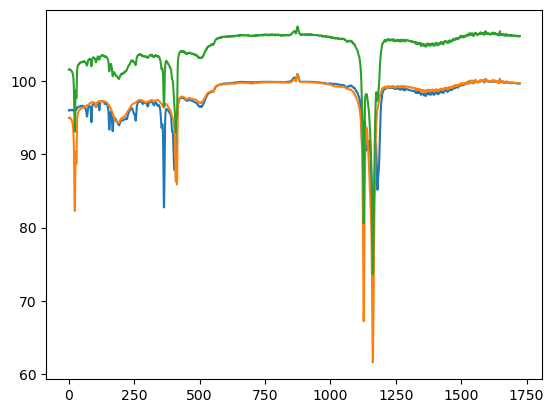

In [236]:
plt.plot(x1.mean(0))
plt.plot(x2.mean(0))
plt.plot(x_out.mean(0))

In [221]:
x1_out.mean(0).shape

torch.Size([1725])

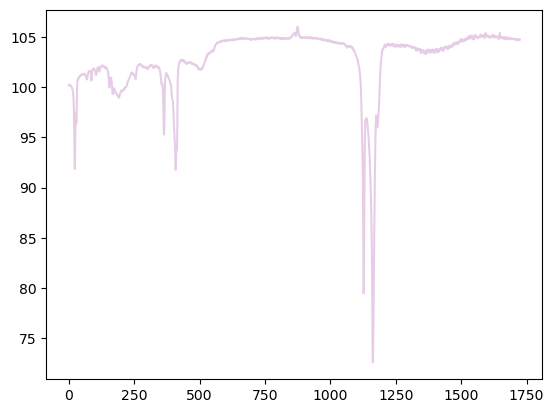

In [222]:
_=plt.plot(x1_out.mean(0), c='r', alpha=.1)
_=plt.plot(x2_out.mean(0), c='b', alpha=.1)

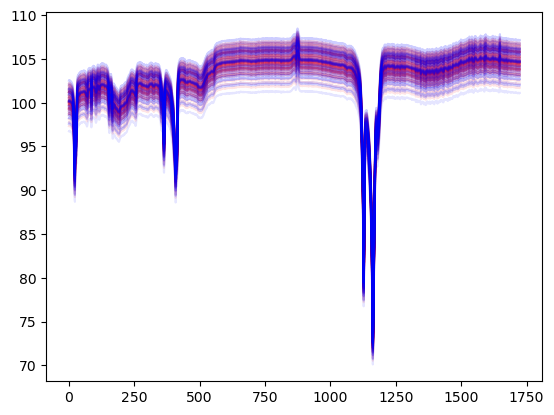

In [223]:
_=plt.plot(x1_out.T, c='r', alpha=.1)
_=plt.plot(x2_out.T, c='b', alpha=.1)

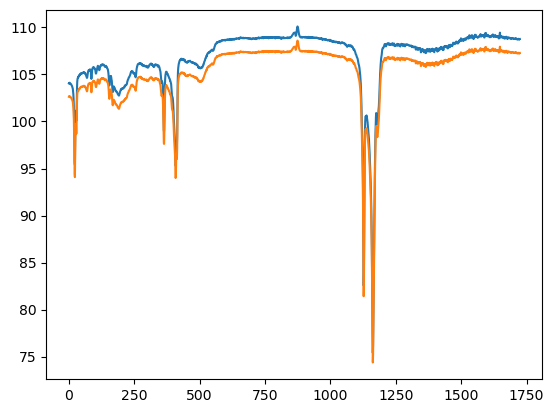

In [235]:
k=150
l=100
plt.plot(x_out[k], label='out')
plt.plot(x_out[l], label='out')

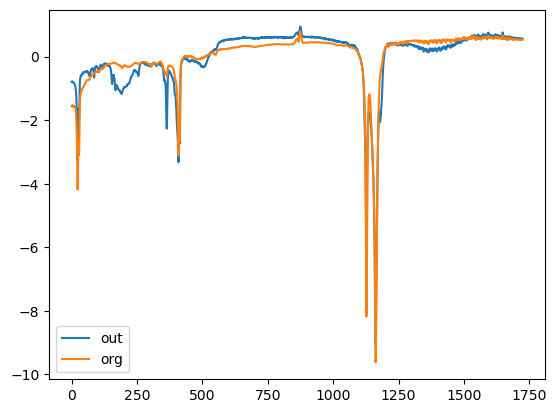

In [233]:
i = 100
j = i%381
#plt.plot(x_out[i], label='out')
plt.plot((x_out[j] - x_out[j].mean()) / (x_out[j].std()), label='out')
#plt.plot(-(x_out[i] - x_out[i].min()) / (x_out[i].min() - x_out[i].max()), label='out')

#plt.plot(x_[i], label='noise')
#plt.plot((x_[i] - x_[i].mean()) / (x_[i].std()), label='noise')
#plt.plot(-(x_[i] - x_[i].min()) / (x_[i].min() - x_[i].max()), label='noise')

#plt.plot(x[j], label='out')
plt.plot((x[j] - x[j].mean()) / (x[j].std()), label='org')
#plt.plot(-(x[j] - x[j].min()) / (x[j].min() - x[j].max()), label='org')

plt.legend()

<AxesSubplot: >

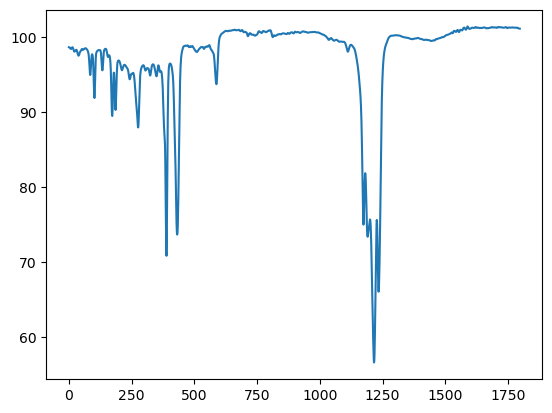

In [304]:
spectra_data.query('file_name == "14 printed  20.2.2020_2020-02-20t13-18-11.csv"')['intensity'].plot()